In [2]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys
import os
sys.path.append(os.path.abspath('C:/Users/Grant/OneDrive/Occami Analytica/Sports Analytics/NBA'))
import db_connection as connector
import matplotlib.pyplot as plt

In [13]:
#Gets all player IDs
try:
    with connector.connect_to_database() as conn:
        cursor = conn.cursor()
        sql_statement = "SELECT DISTINCT id FROM players;"
        cursor.execute(sql_statement)
        result = cursor.fetchall()
        
        player_ids =  [item[0] for item in result]

except Exception as e:
    print(f"Error: {e}")
        

In [ ]:
def create_player_dataframe(player_id, days=3):
    
    data = {'player': [],
            'team': [],
            'boxscore': [],
            'minutes_played': [],
            'field_goals': [],
            'field_goal_attempts': [],
            'three_pointers': [],
            'three_point_attempts': [],
            'free_throws': [],
            'free_throw_attempts': [],
            'offensive_rebounds': [],
            'defensive_rebounds': [],
            'total_rebounds': [],
            'assists': [],
            'steals': [],
            'blocks': [],
            'turnovers': [],
            'fouls': [],
            'points': []}
    
    with connector.connect_to_database() as conn:
        cursor = conn.cursor()
        sql_statement = f"SELECT * FROM player_stats WHERE player = {player_id}"
        cursor.execute(sql_statement)
        result = cursor.fetchall()

    for i in range(len(result)):
        game = result[i]

        data['player'].append(game[1])
        data['team'].append(game[2])
        data['boxscore'].append(game[3])
        data['minutes_played'].append(game[4])
        data['field_goals'].append(game[5])
        data['field_goal_attempts'].append(game[6])
        data['three_pointers'].append(game[7])
        data['three_point_attempts'].append(game[8])
        data['free_throws'].append(game[9])
        data['free_throw_attempts'].append(game[10])
        data['offensive_rebounds'].append(game[11])
        data['defensive_rebounds'].append(game[12])
        data['total_rebounds'].append(game[13])
        data['assists'].append(game[14])
        data['steals'].append(game[15])
        data['blocks'].append(game[16])
        data['turnovers'].append(game[17])
        data['fouls'].append(game[18])
        data['points'].append(game[19])

    df = pd.DataFrame(data)
    
    columns_to_average = ['minutes_played', 'field_goals', 'field_goal_attempts', 'three_pointers', 'three_point_attempts', 'free_throws', 'offensive_rebounds', 'defensive_rebounds', 'total_rebounds', 'assists', 'steals', 'blocks', 'turnovers', 'fouls', 'points']
    
    df[columns_to_average] = df[columns_to_average].rolling(window=days).mean()

    return df.dropna()
    

In [24]:
all_dfs = []

for i in range(len(player_ids)):
    all_dfs.append(create_player_dataframe(player_ids[i]))

df = pd.concat(all_dfs, ignore_index=True)

In [25]:
df.to_csv('Player3DayMovingAverages.csv', index=False)

In [47]:
df = pd.read_csv('Player3DayMovingAverages.csv')

columns_to_analyze = ['minutes_played', 'field_goals', 'field_goal_attempts', 'three_pointers', 'three_point_attempts', 'free_throws', 'free_throw_attempts', 'offensive_rebounds', 'defensive_rebounds', 'total_rebounds', 'assists', 'steals', 'blocks', 'turnovers', 'fouls', 'points']

df_PCA = df[columns_to_analyze]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_PCA)

n_components = 6
pca = PCA(n_components=n_components)
principle_components = pca.fit_transform(scaled_features)

explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

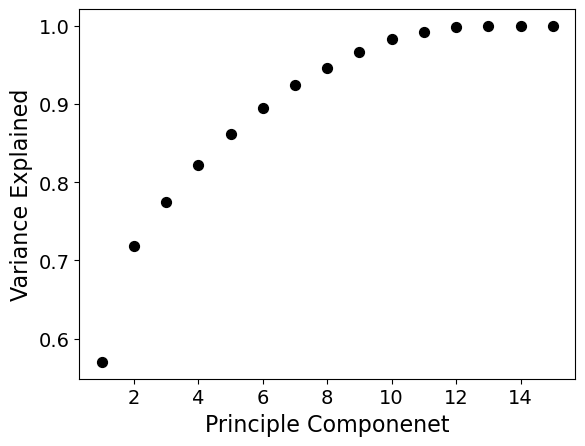

In [19]:
x = np.arange(1, len(cumulative_variance)+1, 1)
plt.scatter(x, cumulative_variance, s=50, c='black')
plt.xlabel('Principle Componenet', fontsize=16)
plt.ylabel('Variance Explained', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.savefig('ExplainedVariancePlot.png', dpi=600, bbox_inches='tight')
plt.show()

In [48]:
components = pca.components_
component_df = pd.DataFrame(components, columns=df_PCA.columns, index=[f'PC{i+1}' for i in range(components.shape[0])])
print("\nComponent Loadings:")
print(component_df)

component_df.to_csv('PrincipleComonents3dayMA.csv')


Component Loadings:
     minutes_played  field_goals  field_goal_attempts  three_pointers  \
PC1        0.309933     0.310686             0.313503        0.207972   
PC2       -0.013954    -0.067789            -0.126440       -0.401522   
PC3       -0.160640     0.004230            -0.007953       -0.323312   
PC4        0.080677    -0.122227            -0.073545       -0.289470   
PC5       -0.010735    -0.069637            -0.065773        0.032916   
PC6       -0.018021     0.005810             0.013697       -0.079679   

     three_point_attempts  free_throws  free_throw_attempts  \
PC1              0.210751     0.259466             0.217804   
PC2             -0.420940    -0.025270             0.025502   
PC3             -0.274647     0.496390             0.602302   
PC4             -0.231844    -0.137983            -0.195257   
PC5              0.035609     0.105605             0.206980   
PC6             -0.051435    -0.075879            -0.229881   

     offensive_rebounds  

In [49]:
n_components = 6
pca = PCA(n_components=n_components)
principle_components = pca.fit_transform(scaled_features)

In [52]:
df = pd.read_csv('Player3DayMovingAverages.csv')

component_names = [f'PC{i+1}' for i in range(6)]

for i, name in enumerate(component_names):
    df[name] = [row[i] for row in principle_components]


In [54]:
df.to_csv('PlayerDataWithPCAs.csv', index=False)